<h1 align="center">Física Computacional.</h1>
<h1 align="center">Tarea Practica 3</h1>

<h2>Alumno: Monroy García Sebástian Dhamar </h2> 

---

1. Grafica de datos experimentales

El archivo manchasolares.txt (adjunto), contiene el numero observado de manchas solares en el Sol en cada mes desde enero de 1749. El archivo contiene dos columnas de numeros, la primera es el mes y la segunda el numero de manchas solares.

(a) Escribe un programa que lea los datos y haga una grafica de las manchas solares en funcion del tiempo.

<function matplotlib.pyplot.show(close=None, block=None)>

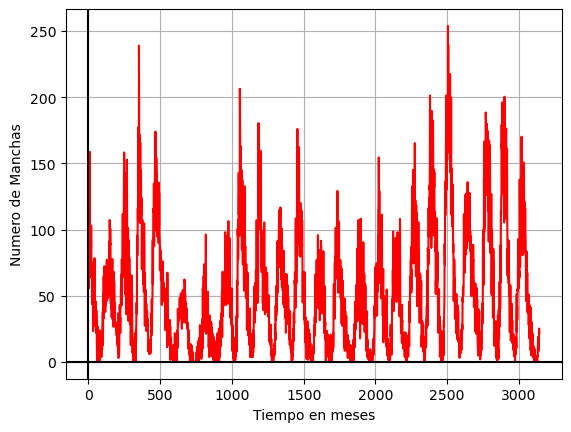

In [15]:
import matplotlib.pyplot as plt
import numpy as np

tiempo=[]
manchas=[]

datos = open("data/manchasolares.txt", "r")
for linea in datos:
    l=linea.split()
    tiempo.append(float(l[0]))
    manchas.append(float(l[1]))

plt.plot(tiempo,manchas, "r")
plt.xlabel("Tiempo en meses")
plt.ylabel("Numero de Manchas")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.grid()
plt.show

---
(b) Modifica tu programa para mostrar solo los primeros 1000 datos (experimentales) en la grafica.

<function matplotlib.pyplot.show(close=None, block=None)>

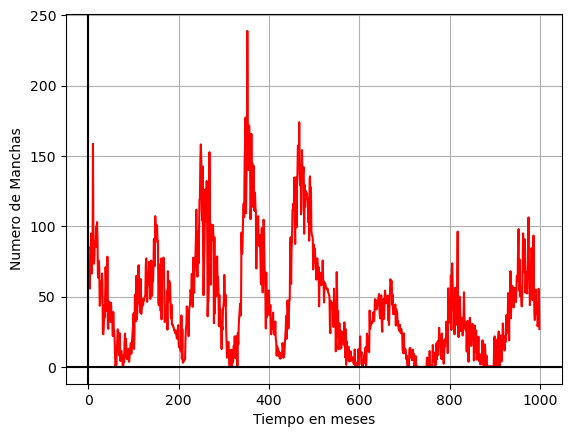

In [16]:
import matplotlib.pyplot as plt
import numpy as np

tiempo=[]
manchas=[]

datos = open("data/manchasolares.txt", "r")
for linea in datos:
    l=linea.split()
    tiempo.append(float(l[0]))
    manchas.append(float(l[1]))
    if len(tiempo)==1000:
        break
    else:
        continue

plt.plot(tiempo,manchas,"r")
plt.xlabel("Tiempo en meses")
plt.ylabel("Numero de Manchas")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.grid()
plt.show

---
(c) Modifica nuevamente tu programa para calcular y graficar la media (promedio) movil de los datos, definida por:

<center>$Y_k=\frac{1}{2r+1}+\sum_{m=-r}^{r}y_{k+m}$<center>

donde r = 5 (en este caso) y $y_k$ son los numeros de manchas solares. 

El programa debe graficar tanto los datos originales como la media movil en el mismo grafico, solo sobre los primeros 1000 datos.

<function matplotlib.pyplot.show(close=None, block=None)>

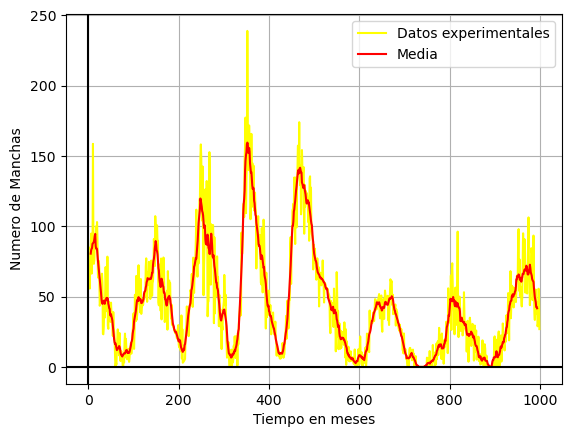

In [21]:
import matplotlib.pyplot as plt
import numpy as np

tiempo=[]
manchas=[]
r=5
Yk=[]
tiempo_Yk=[]

datos = open("data/manchasolares.txt", "r")
for linea in datos:
    l=linea.split()
    tiempo.append(float(l[0]))
    manchas.append(float(l[1]))
    if len(tiempo)==1000:
        break
    else:
        continue

for k in range(r, len(manchas) - r):
    suma = 0.0
    for m in range(-r, r + 1):
        suma = suma+manchas[k + m]
    
    media = (1/((2 * r )+ 1))*suma
    Yk.append(media)
    tiempo_Yk.append(tiempo[k])

plt.plot(tiempo,manchas, label="Datos experimentales", color="yellow")
plt.plot(tiempo_Yk, Yk, "r",label="Media")
plt.xlabel("Tiempo en meses")
plt.ylabel("Numero de Manchas")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()
plt.show

---
---

2. La grafica de Feigenbaum (caos determinista)
   
En un especial halloween de los Simpsons, Homero viaja al pasado a la era Jurasica y por un pequeno descuido cambia el curso de toda la historia en el futuro. Lo anterior es una referencia al cuento A Sound of Thunder de 1952 del escritor de ciencia ficcion Ray Bradbury en donde lo que se destruye en el pasado es una mariposa. Esta idea fue retomada y popularizada por el fisico Edward Lorenz en 1972 cuando dio una
conferencia en la Asociacion Estadounidense para el Avance de la Ciencia ( American Association for the Advancement of Science) titulada “¿El aleteo de una mariposa en Brasil puede provocar un tornado en Texas?. Dando paso al concepto del efecto mariposa, del cual probablemente hayas oido hablar y que es el ejemplo clasico de caos determinista en sistemas climaticos.

El caos determinista tambien aparece en muchos sistemas fisicos mas complejos, incluyendo especialmente la dinamica de fluidos. Debido a su naturaleza aparentemente aleatoria, el comportamiento de los sistemas caoticos es dificil de predecir y se ve fuertemente afectado por pequenas perturbaciones en las condiciones iniciales. Uno de los ejemplos mas famosos del fenomeno del caos determinista es sin duda el mapeo logistico, que es un sistema matematico muy simple, definido por la ecuacion:

<center>$x_{n+1}=rx_n(1-x_n)$<center>

Para un valor dado de la constante r, se toma un valor de xn (digamos x = 12) y se introduce en el lado derecho de esta ecuacion y regresa un valor de xn+1. Luego se toma ese valor y se vuelve a introducir en el lado derecho, lo que da otro valor, y asi sucesivamente. Esto es un mapeo iterativo. Se continua haciendo la misma operacion una y otra vez sobre su valor de xn, y entonces sucede una de las tres siguiente situaciones:

(i) El valor se establece en un numero fijo y permanece alli. Esto se llama punto fijo. Por ejemplo, xn = 0 es siempre un punto fijo del mapeo logistico. (Si se pone xn = 0 en el lado derecho se obtiene xn+1 = 0 en el lado izquierdo).

(ii) No se establece en un solo valor, sino que se establece en un patron periodico, rotando alrededor de un conjunto de valores, digamos cuatro valores, repitiendose en secuencia una y otra vez. Esto se llama orbita (en este caso de periodo 4) o ciclolimite.

(iii) Todo enloquece. El mapeo, genera una secuencia aparentemente aleatoria de numeros que parecen no tener ni patron ni razon (ni ton ni son). Esto es el caos determinista. “Caos” porque realmente parece caotico y “determinista” porque aunque los valores parecen aleatorios, no lo son. Son a todas luces, totalmente predecibles, porque se obtienen mediante una simple ecuacion y el comportamiento esta determinado, aunque no lo parezca.

Responde a las siguientes preguntas:

(a) Apoyate en el programa que vimos en clase y escribe un programa que muestre el comportamiento del mapeo logistico mediante una grafica. 

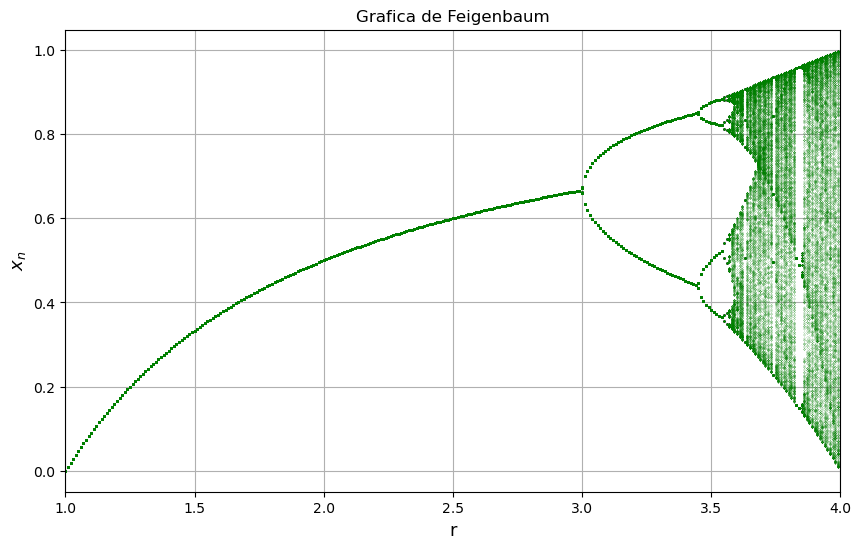

In [45]:
import matplotlib.pyplot as plt
import numpy as np

ran=np.arange(1,4,0.01)

R=[]
Feig=[]
for r in ran:
    xn=0.5
    for _ in range(1000):
        xn = r * xn * (1.0 - xn)
    for _ in range(1000):
        xn = r * xn * (1.0 - xn)
        Feig.append(xn)
        R.append(r)

plt.figure(figsize=(10, 6))
plt.plot(R, Feig, 'g.', markersize=0.2)
plt.title("Grafica de Feigenbaum")
plt.xlabel("r",fontsize=13)
plt.ylabel("$x_n$",fontsize=13)
plt.xlim(1.0, 4.0)
plt.grid()


---
(b) De acuerdo a tu grafica, ¿a que valor de r el sistema pasa de un comportamiento ordenado (puntos fijos o ciclos limite) a un comportamiento caotico? A este punto a veces se le llama “el borde del caos”.

El comportamiento caotico comienza poco despues de 3.5, según valores teoricos hallados por investigacion propia, este punto esta en $r_∞ \approx 3.57$ un valor que coincide de forma aproximada con mi grafica.

---
Hint: Esto es lo que debes hacer para hacer tu programa: Para un valor dado de r, comienza con xn = $\frac{1}{2}$ e itera la ecuacion del mapeo logistico mil veces. Eso le dara la oportunidad de establecerse en un punto fijo o en una orbita de algun periodo. Luego ejecuta otras mil iteraciones y grafica los puntos (r, $x_∞$) en una grafica donde el eje horizontal es r y el eje vertical es $x_∞$.

Puedes usar la funcion plot con las opciones "ko" o "k." para dibujar una grafica con puntos, uno para cada punto, o puedes usar la funcion scatter para dibujar un diagrama de dispersion (que siempre usa puntos). Repite todo el calculo para valores de r de 1 a 4 en pasos de 0.01, graficando los puntos para todos los valores de r en la misma figura. Tu programa deberia generar la distintiva grafica que parece un arbol inclinado hacia un lado. Esta famosa imagen se llama Grafica de Feigenbaum, en honor a su descubridor Mitchell Feigenbaum.

---
(c) ** Opcional (para 1.5 puntos extra): Hay otra forma para calcular el diagrama de Feigenbaum, que puede ser mas claro y rapido, dado que hace uso de la capacidad de Python para realizar aritmetica con arreglos completos. Crear un arreglo r que contenga cada valor distinto de r, [1.0, 1.01, 1.02, ... ]. Crea otro arreglo x del mismo tamano para guardar los valores correspondientes de x, establecidos inicialmente en 0.5; finalmente realiza una iteracion del mapeo logistico para todos los valores de r a la vez, con una sola instruccion de la forma x = r*x*(1-x) y comparala con tu programa anterior.

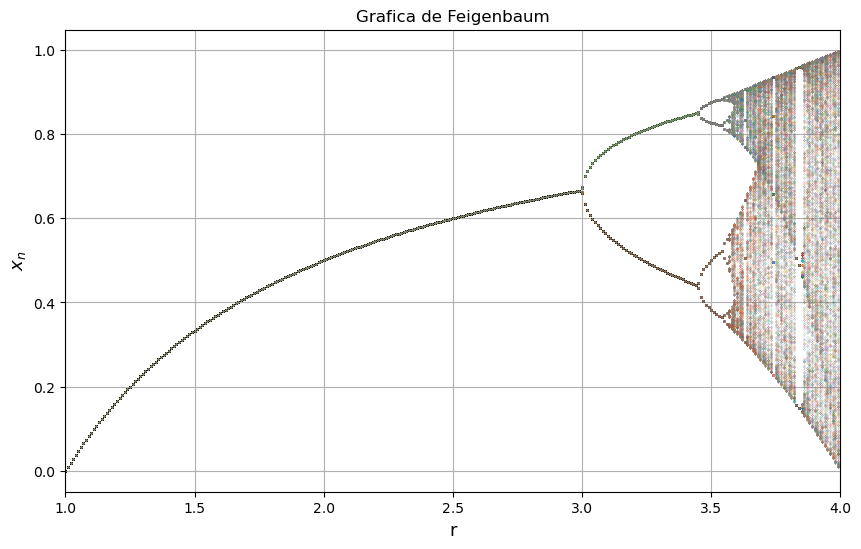

In [46]:
import matplotlib.pyplot as plt
import numpy as np

ran=np.arange(1,4,0.01)
r=np.array(ran)
x=np.full(len(r), 0.5)

plt.figure(figsize=(10, 6))

for _ in range(1000):
    x = r*x*(1-x)
for _ in range(1000):
    x = r*x*(1-x)
    plt.plot(r, x, '.', markersize=0.2)
# x = r*x*(1-x)
# r.map(x = r*x*(1-x))

# plt.plot(r, x, '.',color="green")
plt.title("Grafica de Feigenbaum")
plt.xlabel("r",fontsize=13)
plt.ylabel("$x_n$",fontsize=13)
plt.xlim(1.0, 4.0)
plt.grid()
plt.show()

Usando unarreglo con los valores de r en lugar de un for para r, el resultado es el mismo.

---
---
3. El conjunto de Mandelbrot
El conjunto de Mandelbrot, llamado asi por su descubridor, el matematico frances Benoit Mandelbrot, es un fractal; un objeto matematico infinitamente ramificado que contiene estructura dentro de estructura dentro de estructura, tan profundamente como
queramos mirar. La definicion del conjunto de Mandelbrot en terminos de numeros complejos es la siguiente.

Consideremos la ecuacion: 

<center> $z_{n+1}=z_n^2+c, \qquad  z_n,c \in \mathbb{C}$</center>

donde $z_n$ es un numero complejo y c es una constante compleja. De manera, muy similar al mapeo logistico, la definicion del conjunto de Mandelbrot implica la iteracion repetida de esta ecuacion para cualquier valor dado de c. La ecuacion convierte un numero de entrada $z_n$ en un numero de salida ´ zn+1; de tal manera que se toma un valor inicial de $z_0$ y se introduce en la ecuacion para obtener un nuevo valor $z_1$, luego tomamos ese valor y lo volvemos a introducir para obtener $z_2$ y asi sucesivamente.

Asi, el conjunto de Mandelbrot es el conjunto de puntos del plano complejo que satisface la siguiente definicion:

*<center>Para un valor dado de c y la condicion inicial $z_0$ = 0; si al iterar repetidamente la ecuación, la magnitud del valor resultante es mayor a dos (i.e. |$z_∞$| > 2), entonces el punto del plano complejo para ese valor c no esta en el conjunto de Mandelbrot; de lo contrario, si esta en el conjunto.</center>*

Para utilizar esta definicion, en principio, habria que iterar infinitas veces para demostrar que un punto esta en el conjunto de Mandelbrot, ya que un punto esta en el conjunto solo si la iteracion nunca pasa de |zn| = 2. Sin embargo, en la practica, simplemente se realiza una gran cantidad de iteraciones (digamos 100) y si |zn| no ha excedido 2 en ese momento, entonces lo consideramos suficientemente bueno.

---

(a) Escribe un programa para crear una imagen del conjunto de Mandelbrot realizando la iteracion para todos los valores de c = x + iy en una cuadricula de N × N que abarque la region donde −2 ≤ x ≤ 2 y −2 ≤ y ≤ 2. Haz una grafica de densidad (density plot) en el que los puntos de la cuadricula dentro del conjunto de Mandelbrot esten coloreados en negro y los de afuera estén coloreados en blanco.

Sugerencia: Probablemente te resulte util comenzar con una cuadricula muy simple, es decir, con un valor pequeno de N (quizas N = 100) para que tu programa se ejecute rapidamente mientras lo pruebas. Una vez que te asegures de que funciona correctamente, aumenta el valor de N para producir una imagen final de alta calidad de la forma del conjunto.

/tmp/ipykernel_6938/1060142974.py:15: RuntimeWarning: overflow encountered in square
  z=(z**2)+c
/tmp/ipykernel_6938/1060142974.py:15: RuntimeWarning: invalid value encountered in square
  z=(z**2)+c


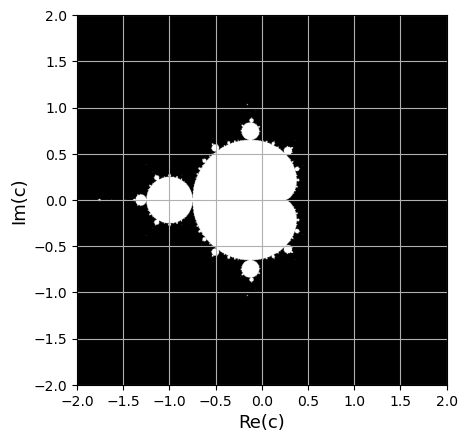

In [39]:
import matplotlib.pyplot as plt
import numpy as np

z=0+(1j*0)
n = 1000
N = 500
cman=np.zeros((n,n))
x=np.linspace(-2,2,n)
y=np.linspace(-2,2,n)
X,Y=np.meshgrid(x,y)

c=X+(Y*1j)

for i in range(N):
    z=(z**2)+c
for k in range(len(z)):
    for h in range(len(z)):
        if np.abs(z[k][h])<2:
            cman[k][h]=1

plt.imshow(cman, extent=[-2, 2, -2, 2],origin='lower')
plt.xlabel("Re(c)",fontsize=13)
plt.ylabel("Im(c)",fontsize=13)
plt.grid()
plt.gray()

(b) ** Opcional (para 1.5 puntos extra): Si te aburrio lo anterior (o te resulto demasiado facil), puedes programar otra variante del mismo ejercicio que puede producir imagenes sorprendentes. En lugar de colorear los puntos solo en blanco o negro, 
colorea los puntos de acuerdo con el numero de iteraciones de la ecuacion antes de que |zn| sea mayor que 2 (o bien el numero maximo de iteraciones si es que |zn| nunca llega a ser mayor que 2). Si usas alguno de los esquemas mas coloridos que Python proporciona para las graficas de densidad, como “hot” or “jet”, puedes crear algunas imagenes muy espectaculares. Otra variante interesante es colorear segun el logaritmo del numero de iteraciones, lo que ayuda a revelar parte de la estructura mas fina fuera del conjunto.

/tmp/ipykernel_6938/3071422596.py:19: RuntimeWarning: overflow encountered in square
  z=(z**2)+c
/tmp/ipykernel_6938/3071422596.py:19: RuntimeWarning: invalid value encountered in square
  z=(z**2)+c


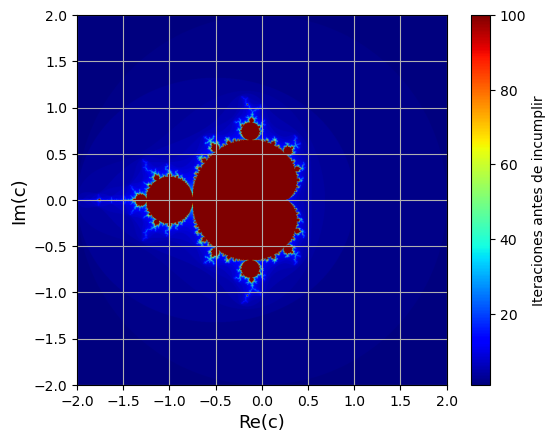

In [42]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
n = 100

x = np.linspace(-2, 2, N)
y = np.linspace(-2, 2, N)
X, Y = np.meshgrid(x, y)

c = X + 1j * Y
z = np.zeros_like(c)

itera=np.zeros((N,N))

for _ in range(n):
    NoSalen=np.abs(z)<=2
    itera = itera+NoSalen
    z=(z**2)+c

plt.imshow(itera, extent=[-2, 2, -2, 2], origin='lower')
plt.colorbar(label="Iteraciones antes de incumplir")
plt.xlabel("Re(c)", fontsize=13)
plt.ylabel("Im(c)", fontsize=13)
plt.grid()
plt.jet()